# Gate 1: looking at the walks

For every run in `runs/*_s*`: path map, contact sheet, stats table against the subset's base rates,
held-out learning curve, plus two diagnostics for the noisy-TV test and seed divergence.

**Pass if** (a) at least one agent's stats clearly differ from `random`; (b) `baseline` visits fewer
cloudy/noise tiles than `novelty_only`; (c) seeds and temperaments produce visibly different paths.
Noise here = the synthetic noisy-TV cluster (fresh noise per look) plus real clouds (max 25 % in Major TOM).

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
ROOT = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
idx = pd.read_parquet(ROOT/'data/tiles.parquet')
tiles = np.load(ROOT/'data/tiles.npy', mmap_mode='r')
ORDER = ['random', 'baseline', 'novelty_only', 'surprise_only', 'myopic', 'wide', 'restless', 'tvtest_baseline', 'tvtest_novelty_only', 'tvtest_surprise_only']
runs = sorted([p for p in (ROOT/'runs').glob('*_s*') if (p/'steps.parquet').exists()],
              key=lambda p: (ORDER.index(p.name.rsplit('_s', 1)[0]) if p.name.rsplit('_s', 1)[0] in ORDER else 99, p.name))
steps = {p.name: pd.read_parquet(p/'steps.parquet') for p in runs}
cands = {p.name: pd.read_parquet(p/'candidates.parquet') for p in runs if (p/'candidates.parquet').exists()}
held = {p.name: pd.read_parquet(p/'heldout.parquet') for p in runs if (p/'heldout.parquet').exists()}
meta = {p.name: json.loads((p/'meta.json').read_text()) for p in runs}
print(len(idx), 'tiles;', len(runs), 'runs:', [p.name for p in runs])
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.precision', 3)

1814 tiles; 20 runs: ['random_s0', 'random_s1', 'baseline_s0', 'baseline_s1', 'novelty_only_s0', 'novelty_only_s1', 'surprise_only_s0', 'surprise_only_s1', 'myopic_s0', 'myopic_s1', 'wide_s0', 'wide_s1', 'restless_s0', 'restless_s1', 'tvtest_baseline_s0', 'tvtest_baseline_s1', 'tvtest_novelty_only_s0', 'tvtest_novelty_only_s1', 'tvtest_surprise_only_s0', 'tvtest_surprise_only_s1']


## Base rates of the subset
What a walker that ignored content would see on average.

In [2]:
nb = np.load(ROOT/'data/neighbours_15km.npz')
import sys; sys.path.insert(0, str(ROOT/'data'))
from prepare import haversine_km
src = np.repeat(np.arange(len(idx)), np.diff(nb['indptr']))
nd = haversine_km(idx.lat.values[src], idx.lon.values[src], idx.lat.values[nb['indices']], idx.lon.values[nb['indices']])
base = pd.Series({
    'tiles': len(idx), 'tv_tiles': int(idx.tv.sum()), 'tv_frac': idx.tv.mean(),
    'mean_cloud_cover': idx.cloud_cover.mean(), 'frac_cloud_gt10': (idx.cloud_cover > 10).mean(),
    'mean_neighbours_15km': np.diff(nb['indptr']).mean(), 'mean_neighbour_dist_km': nd.mean(),
})
base.to_frame('subset')

,subset
tiles,1814.000
tv_tiles,7.000
tv_frac,0.004
mean_cloud_cover,1.191
frac_cloud_gt10,0.047
mean_neighbours_15km,6.740
mean_neighbour_dist_km,11.687


## Stats table
`revisit_rate` = 1 − unique/steps. `rg_km` = radius of gyration of the path, `net_km` = start→end distance.
`tv_steps` = share of steps on noisy-TV tiles; `first_tv` = step of first TV visit; `max_tv_dwell` = longest run of consecutive TV steps.
`cloud` = mean cloud cover of visited (non-TV) tiles vs the subset base rate.

In [3]:
def path_stats(name, s):
    lat, lon = s.lat.values, s.lon.values
    clat, clon = lat.mean(), lon.mean()
    rg = np.sqrt(np.mean(haversine_km(lat, lon, clat, clon) ** 2))
    tvs = s.tv.values.astype(int)
    runs_tv = np.diff(np.flatnonzero(np.diff(np.r_[0, tvs, 0])))[::2] if tvs.any() else [0]
    nontv = s[~s.tv]
    return {
        'run': name, 'steps': len(s), 'unique': s.tile_idx.nunique(), 'revisit_rate': 1 - s.tile_idx.nunique() / len(s),
        'mean_step_km': s.dist_km.iloc[1:].mean(), 'median_step_km': s.dist_km.iloc[1:].median(),
        'rg_km': rg, 'net_km': haversine_km(lat[0], lon[0], lat[-1], lon[-1]),
        'long_jumps': int((s.jump_type == 'long').sum()), 'bored_events': int(s.bored_event.sum()),
        'tv_steps': s.tv.mean(), 'tv_unique': s[s.tv].tile_idx.nunique(),
        'first_tv': int(s.step[s.tv].min()) if s.tv.any() else -1, 'max_tv_dwell': int(max(runs_tv)),
        'cloud': nontv.cloud_cover.mean(), 'cloud_vs_base': nontv.cloud_cover.mean() / idx[~idx.tv].cloud_cover.mean(),
        'frac_cloud_gt10': (nontv.cloud_cover > 10).mean(),
        'lat_mean': lat.mean(), 'frac_alps_lat_gt_45_8': (lat > 45.8).mean(),
        'minutes': meta[name].get('seconds', np.nan) / 60,
    }
stats = pd.DataFrame([path_stats(k, v) for k, v in steps.items()]).set_index('run')
stats

,steps,unique,revisit_rate,mean_step_km,median_step_km,rg_km,net_km,long_jumps,bored_events,tv_steps,tv_unique,first_tv,max_tv_dwell,cloud,cloud_vs_base,frac_cloud_gt10,lat_mean,frac_alps_lat_gt_45_8,minutes
run,,,,,,,,,,,,,,,,,,,
random_s0,1500,501,0.666,11.413,10.085,118.847,37.989,0,0,1.333e-03,2,20,2,1.187,0.993,0.051,45.086,0.306,0.003
random_s1,1500,609,0.594,11.794,10.080,150.652,193.383,0,0,0.000e+00,0,-1,0,1.526,1.277,0.061,45.191,0.381,0.003
baseline_s0,1500,434,0.711,13.250,10.083,156.271,200.516,5,5,1.067e-02,7,11,7,1.382,1.155,0.057,45.331,0.511,1.493
baseline_s1,1500,419,0.721,13.133,10.111,177.575,157.204,5,4,0.000e+00,0,-1,0,1.660,1.388,0.063,45.495,0.517,1.280
novelty_only_s0,1500,292,0.805,13.369,10.093,181.470,170.031,4,4,0.000e+00,0,-1,0,1.639,1.370,0.055,45.328,0.428,1.327
novelty_only_s1,1500,279,0.814,12.573,10.073,133.355,237.531,2,2,0.000e+00,0,-1,0,0.845,0.707,0.036,46.001,0.754,1.205
surprise_only_s0,1500,113,0.925,12.451,13.420,63.682,189.589,0,2,6.667e-04,1,4,1,0.148,0.123,0.005,46.415,0.975,1.268
surprise_only_s1,1500,113,0.925,12.256,10.031,72.326,211.000,2,2,0.000e+00,0,-1,0,0.930,0.778,0.025,46.168,0.968,1.290
myopic_s0,1500,365,0.757,12.743,10.073,145.458,154.187,5,4,4.667e-03,3,15,3,0.808,0.676,0.035,46.010,0.728,1.168


Grouped by temperament (mean of seeds), with the random walk as reference.

In [4]:
g = stats.copy(); g['temperament'] = [r.rsplit('_s', 1)[0] for r in g.index]
cols = ['unique', 'revisit_rate', 'mean_step_km', 'rg_km', 'net_km', 'bored_events', 'tv_steps', 'max_tv_dwell', 'cloud_vs_base', 'frac_alps_lat_gt_45_8']
gm = g.groupby('temperament', sort=False)[cols].mean()
gm

,unique,revisit_rate,mean_step_km,rg_km,net_km,bored_events,tv_steps,max_tv_dwell,cloud_vs_base,frac_alps_lat_gt_45_8
temperament,,,,,,,,,,
random,555.0,0.630,11.603,134.749,115.686,0.0,6.667e-04,1.0,1.135,0.343
baseline,426.5,0.716,13.192,166.923,178.860,4.5,5.333e-03,3.5,1.272,0.514
novelty_only,285.5,0.810,12.971,157.412,203.781,3.0,0.000e+00,0.0,1.038,0.591
surprise_only,113.0,0.925,12.353,68.004,200.294,2.0,3.333e-04,0.5,0.451,0.971
myopic,340.5,0.773,13.058,185.089,174.933,5.5,2.333e-03,1.5,0.979,0.569
wide,387.5,0.742,13.019,141.808,205.283,6.0,2.667e-03,2.5,1.170,0.692
restless,332.5,0.778,14.461,147.101,186.573,19.0,4.333e-03,4.0,0.767,0.573
tvtest_baseline,345.0,0.770,12.937,157.552,183.610,4.0,0.000e+00,0.0,1.096,0.481
tvtest_novelty_only,227.5,0.848,12.556,124.538,183.482,1.5,4.000e-03,4.5,1.383,0.354


## Path maps
Background: every tile pasted at its position (equirectangular km). Line coloured by step (dark→yellow), white x = bored event, magenta ring = noisy-TV cluster, green dot = start.

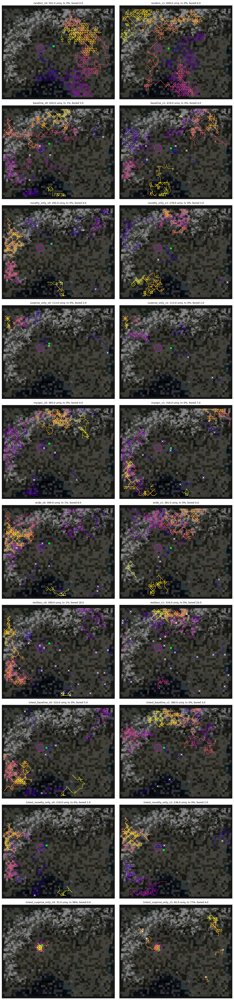

In [5]:
LAT0 = 45.25
def to_km(lat, lon):
    return (np.asarray(lon) - 6.4) * np.cos(np.radians(LAT0)) * 111.32, (np.asarray(lat) - 43.4) * 110.57
PX = 0.5  # km per canvas pixel
W, H = int(to_km(47.1, 12.7)[0] / PX), int(to_km(47.1, 12.7)[1] / PX)
canvas = np.full((H, W, 3), 40, np.uint8)
xs, ys = to_km(idx.lat.values, idx.lon.values)
tpx = int(round(10.68 / PX))
for i in range(len(idx)):
    t = np.asarray(Image.fromarray(np.asarray(tiles[i])).resize((tpx, tpx), Image.Resampling.BOX))
    cx, cy = int(xs[i] / PX), H - int(ys[i] / PX)
    y0, x0 = max(cy - tpx // 2, 0), max(cx - tpx // 2, 0)
    canvas[y0:y0 + tpx, x0:x0 + tpx] = t[: H - y0, : W - x0][: min(tpx, H - y0), : min(tpx, W - x0)]
canvas_dim = (canvas * 0.55).astype(np.uint8)
tvx, tvy = to_km(45.40, 8.55)

def path_map(ax, name):
    s = steps[name]
    x, y = to_km(s.lat.values, s.lon.values)
    ax.imshow(canvas_dim, extent=(0, W * PX, 0, H * PX))
    jump = s.jump_type.values != 'neighbour'
    seg_x, seg_y = x.copy(), y.copy()
    seg_x[jump], seg_y[jump] = np.nan, np.nan   # break the line at jumps
    from matplotlib.collections import LineCollection
    pts = np.stack([x, y], 1)
    segs = np.stack([pts[:-1], pts[1:]], 1)[~jump[1:]]
    lc = LineCollection(segs, cmap='plasma', linewidths=1.2)
    lc.set_array(np.arange(len(s) - 1)[~jump[1:]]); ax.add_collection(lc)
    ax.scatter(x[jump], y[jump], s=10, c=np.flatnonzero(jump), cmap='plasma', vmin=0, vmax=len(s), marker='o', edgecolors='w', linewidths=0.4, zorder=4)
    b = s.bored_event.values
    ax.scatter(x[b], y[b], s=40, c='w', marker='x', zorder=5)
    ax.scatter(x[:1], y[:1], s=50, c='lime', zorder=6)
    ax.add_patch(plt.Circle((tvx, tvy), 16, fill=False, ec='magenta', lw=1.2))
    st = stats.loc[name]
    ax.set_title(f"{name}: {st['unique']} uniq, tv {st['tv_steps']:.0%}, bored {st['bored_events']}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

n = len(runs); ncol = 2; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 5.3 * nrow))
for ax, p in zip(axes.flat, runs): path_map(ax, p.name)
for ax in axes.flat[n:]: ax.axis('off')
fig.tight_layout(); fig.savefig(ROOT/'notes/img/gate1_paths.png', dpi=60); plt.show()

## Visit density
Where each temperament spends its time (both seeds pooled), as tile visit counts.

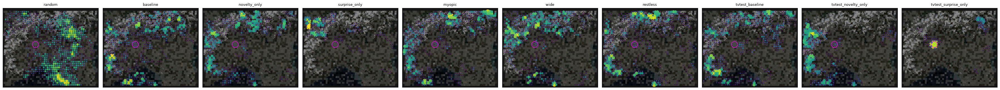

In [6]:
temps = list(dict.fromkeys(r.rsplit('_s', 1)[0] for r in steps))
fig, axes = plt.subplots(1, len(temps), figsize=(3.6 * len(temps), 3.4))
for ax, tname in zip(np.atleast_1d(axes), temps):
    s = pd.concat([v for k, v in steps.items() if k.rsplit('_s', 1)[0] == tname])
    c = s.tile_idx.value_counts()
    ax.imshow(canvas_dim, extent=(0, W * PX, 0, H * PX))
    ax.scatter(xs[c.index], ys[c.index], s=np.clip(c.values, 1, 60) * 2, c=np.log1p(c.values), cmap='viridis', alpha=0.9)
    ax.add_patch(plt.Circle((tvx, tvy), 16, fill=False, ec='magenta', lw=1))
    ax.set_title(tname, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

## Contact sheets
Every 10th visited tile, in order (read left→right, top→bottom). Red frame = noisy TV, white frame = bored teleport.

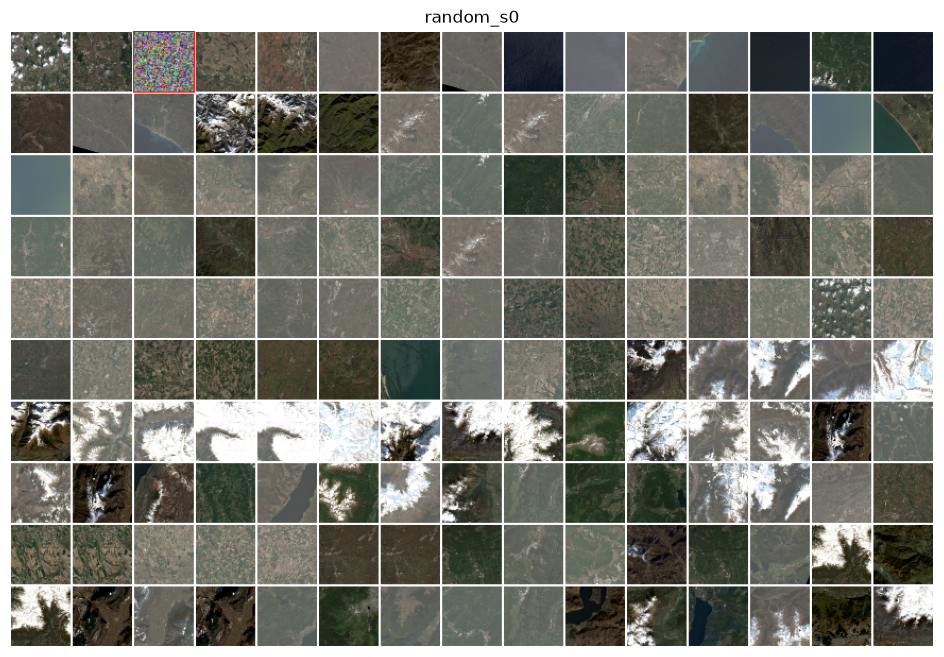

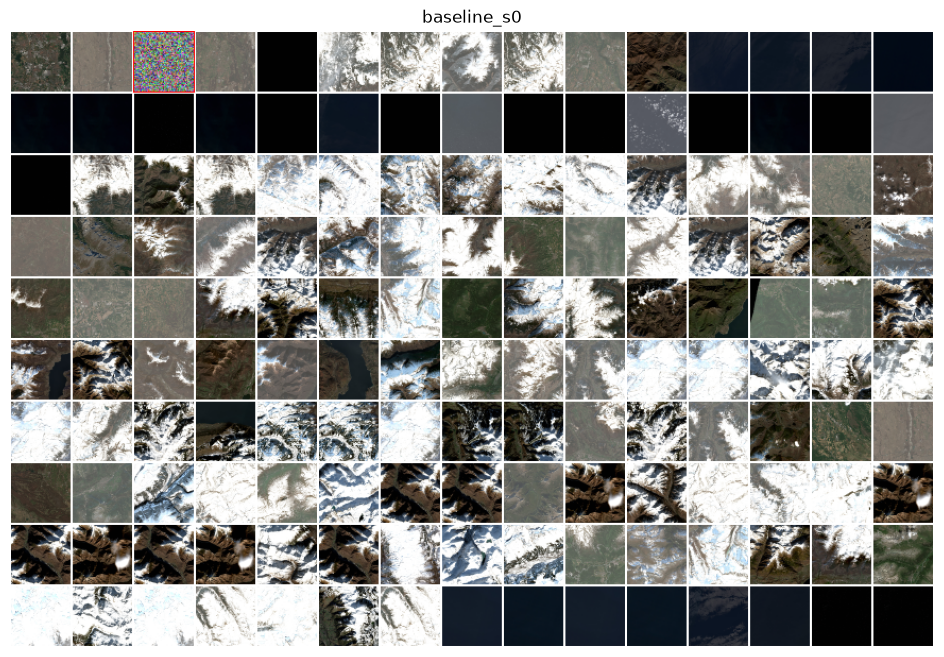

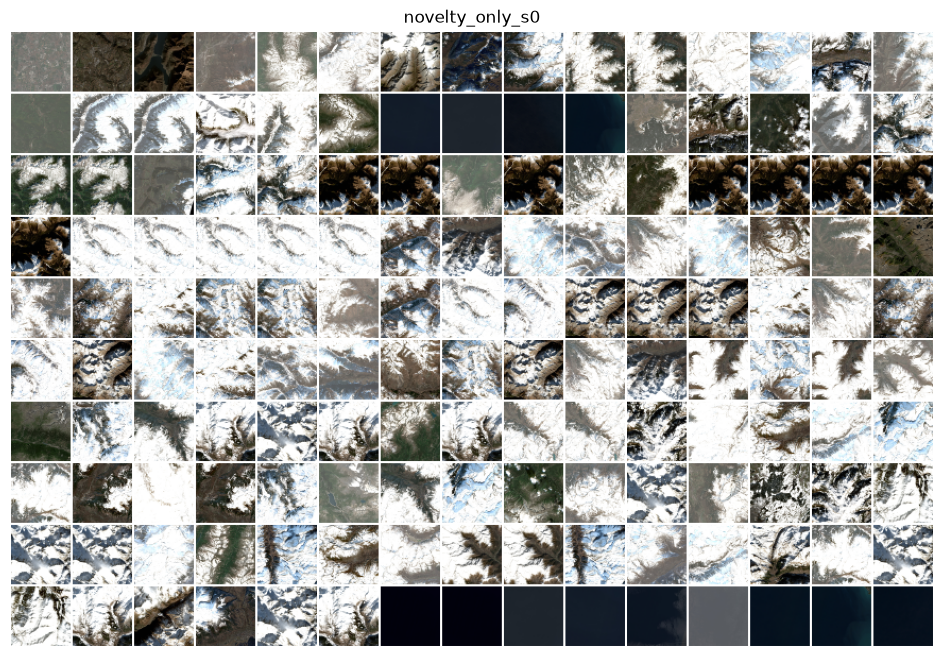

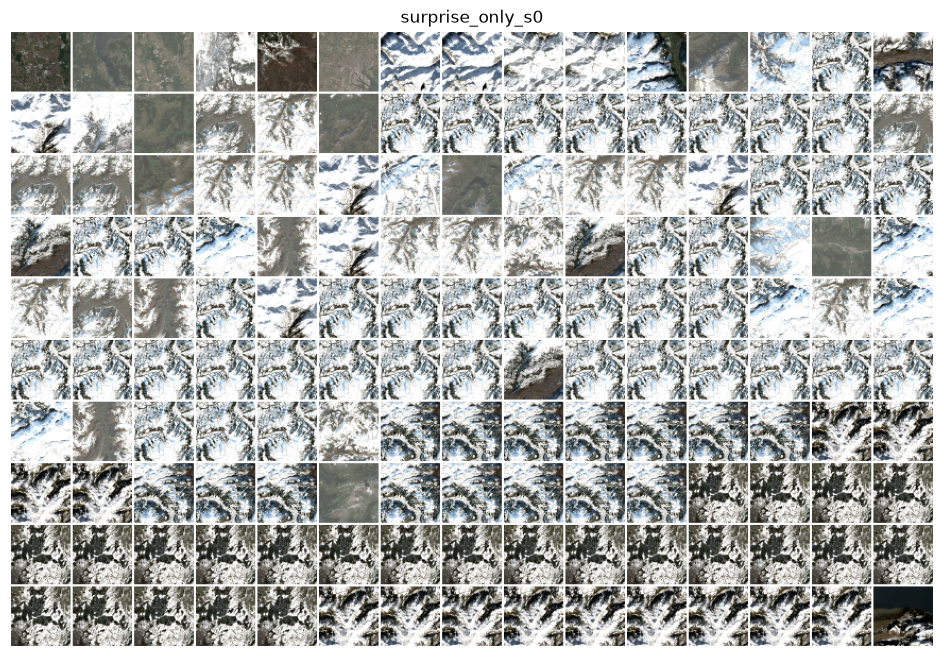

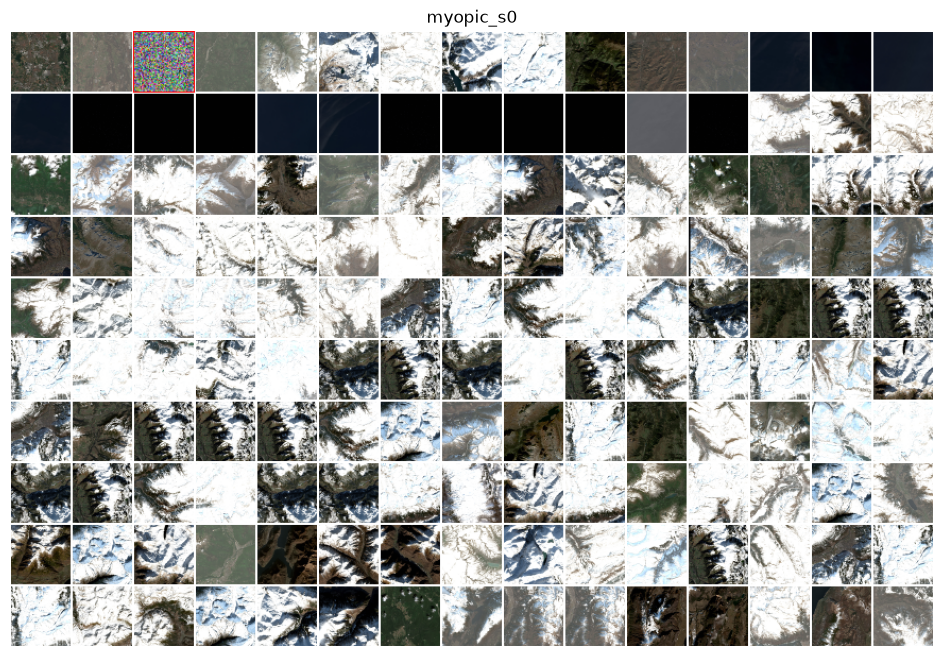

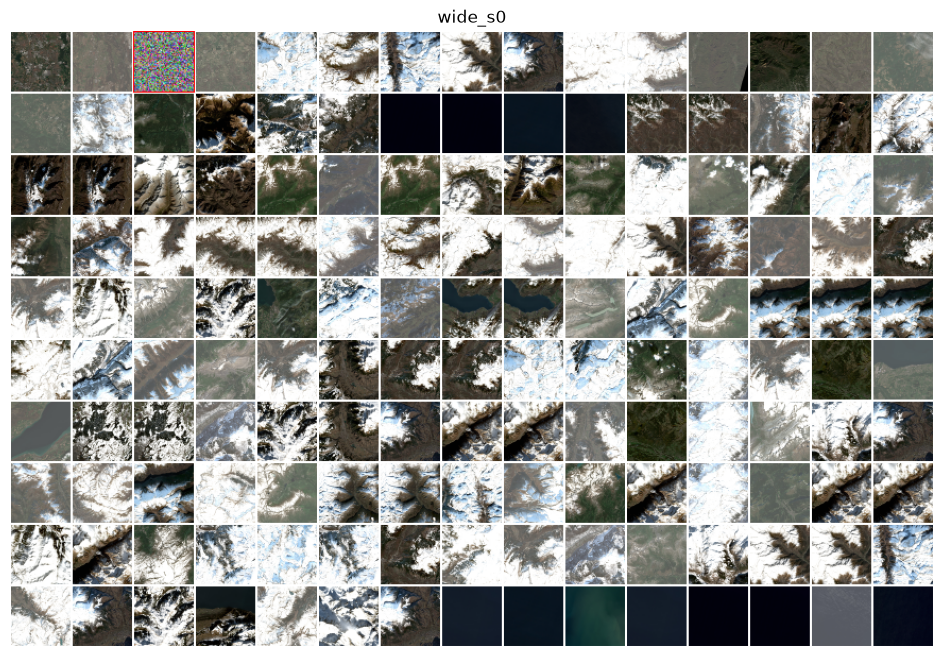

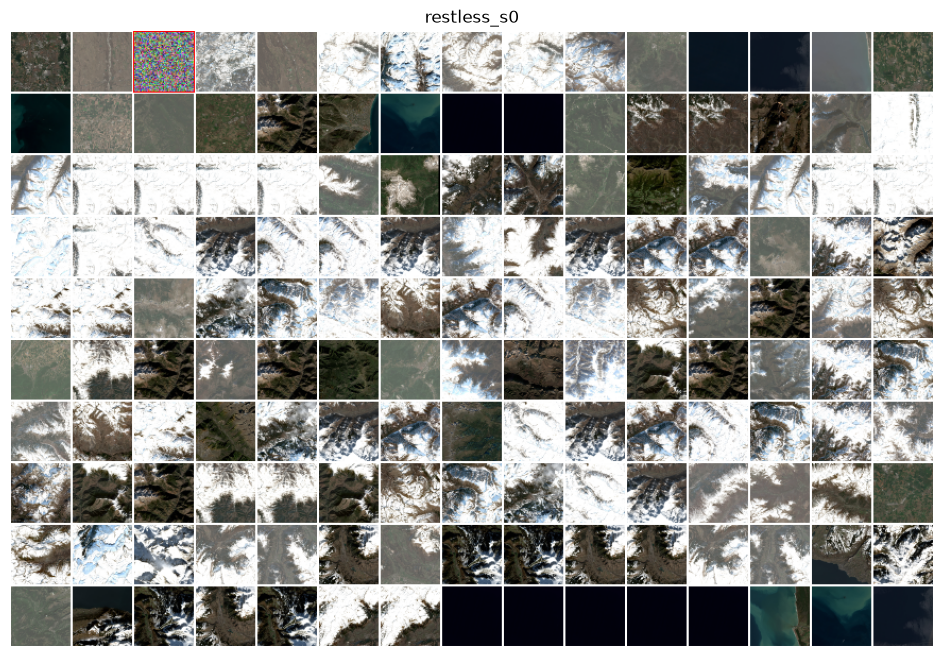

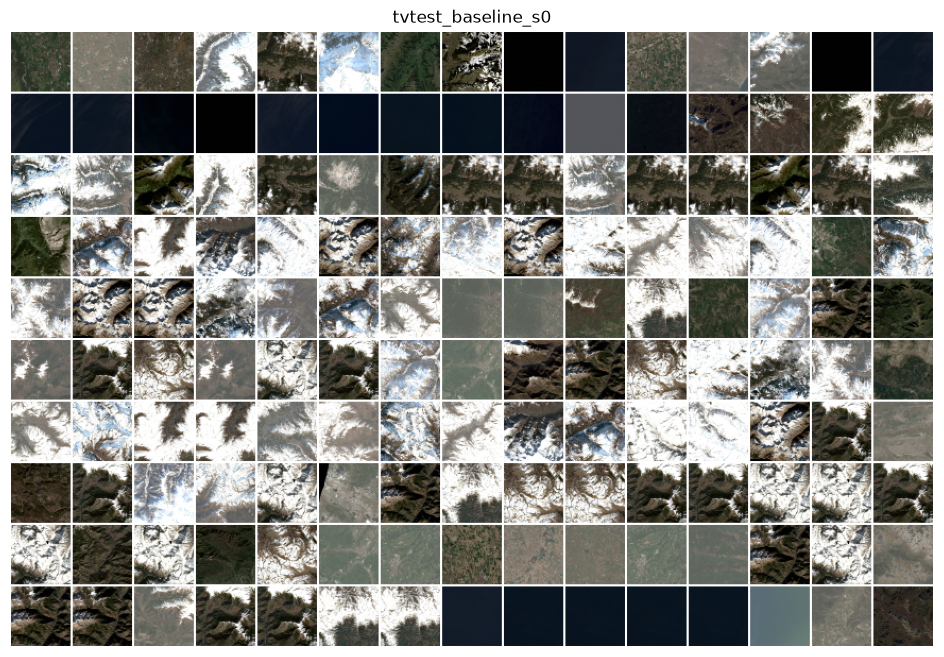

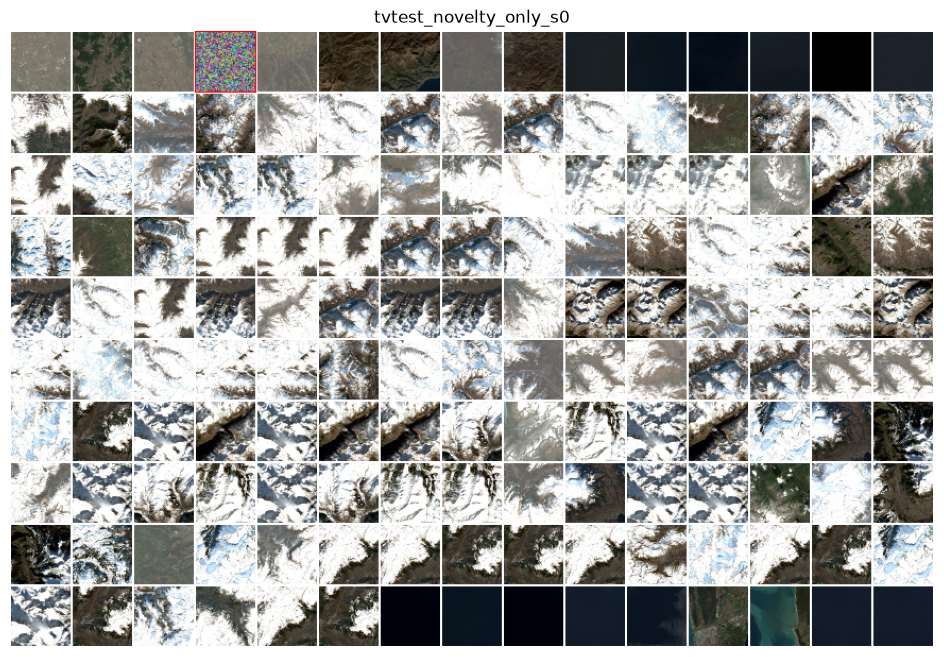

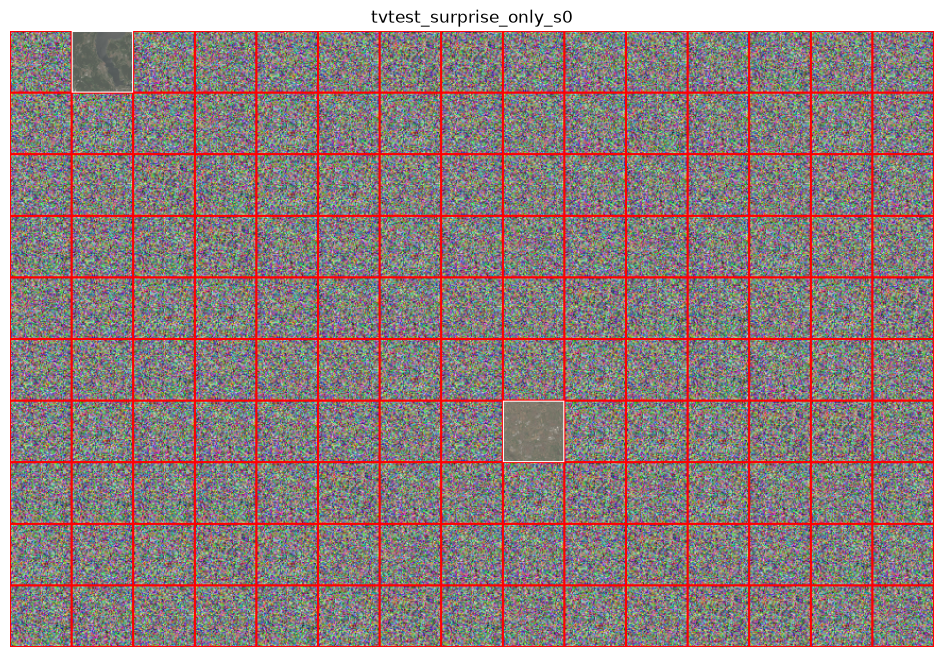

In [7]:
def contact_sheet(name, every=10, ncol=15, px=56):
    s = steps[name].iloc[::every]
    rows = int(np.ceil(len(s) / ncol))
    sheet = np.full((rows * (px + 2), ncol * (px + 2), 3), 255, np.uint8)
    for k, r in enumerate(s.itertuples()):
        im = np.asarray(Image.fromarray(np.asarray(tiles[r.tile_idx])).resize((px, px), Image.Resampling.BOX))
        y0, x0 = (k // ncol) * (px + 2), (k % ncol) * (px + 2)
        col = (255, 0, 0) if r.tv else (255, 255, 255) if r.jump_type == 'bored' else None
        if col: sheet[y0:y0 + px + 2, x0:x0 + px + 2] = col
        sheet[y0 + 1:y0 + 1 + px, x0 + 1:x0 + 1 + px] = im
    return sheet

for p in runs:
    sh = contact_sheet(p.name)
    Image.fromarray(sh).save(ROOT/f'notes/img/gate1_contact_{p.name}.png')
    if not p.name.endswith('_s0'): continue   # all sheets are saved to notes/img; seed 0 shown inline
    plt.figure(figsize=(12, 12 * sh.shape[0] / sh.shape[1])); plt.imshow(sh); plt.axis('off'); plt.title(p.name); plt.show()

## Learning curves
Reconstruction MSE on the fixed 200-tile held-out probe (each agent at its own crop scale, so compare within a scale).

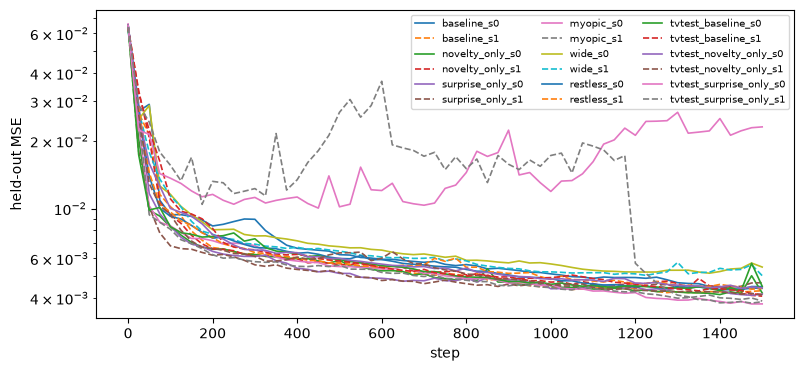

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
for k, h in held.items():
    ax.plot(h.step, h.heldout_mse, label=k, lw=1.2, ls='-' if k.endswith('_s0') else '--')
ax.set_yscale('log'); ax.set_xlabel('step'); ax.set_ylabel('held-out MSE'); ax.legend(fontsize=7, ncol=3); plt.show()

## Noisy-TV diagnostic
For every step where a TV tile was among the candidates: its z-scores vs the other candidates'.
Novelty should be high for TV; progress should be low. Also: the chosen-tile signals over time.

In [9]:
rows = []
for k, c in cands.items():
    c = c.merge(idx[['idx', 'tv', 'cloud_cover']], left_on='tile_idx', right_on='idx')
    tv_steps = c.step[c.tv].unique()
    cc = c[c.step.isin(tv_steps)]
    for is_tv, grp in cc.groupby('tv'):
        rows.append({'run': k, 'tv_candidate': is_tv, 'n': len(grp), 'n_z': grp.n_z.mean(), 'g_z': grp.g_z.mean(), 'e_z': grp.e_z.mean(), 'I': grp.I.mean(), 'p_chosen': grp.p.mean(), 'chosen_rate': grp.chosen.mean()})
    cl = c[~c.tv]
    for hi, grp in cl.groupby(cl.cloud_cover > 10):
        rows.append({'run': k, 'tv_candidate': f'real cloud>10%: {hi}', 'n': len(grp), 'n_z': grp.n_z.mean(), 'g_z': grp.g_z.mean(), 'e_z': grp.e_z.mean(), 'I': grp.I.mean(), 'p_chosen': grp.p.mean(), 'chosen_rate': grp.chosen.mean()})
tvdiag = pd.DataFrame(rows).set_index(['run', 'tv_candidate'])
tvdiag

n    n_z    g_z    e_z      I  p_chosen  chosen_rate
run                     tv_candidate                                                                   
baseline_s0             False                    161 -0.504 -0.112 -0.818 -0.616     0.101        0.099
                        True                      94  0.164 -0.226  2.217 -0.062     0.168        0.170
                        real cloud>10%: False  10031 -0.041 -0.063 -0.072 -0.104     0.139        0.140
                        real cloud>10%: True     785 -0.194  0.044 -0.025 -0.150     0.113        0.107
baseline_s1             real cloud>10%: False   9761 -0.079 -0.033 -0.098 -0.111     0.145        0.144
                        real cloud>10%: True     674 -0.156  0.100  0.122 -0.056     0.125        0.139
novelty_only_s0         real cloud>10%: False   9998 -0.034 -0.034 -0.083 -0.034     0.142        0.142
                        real cloud>10%: True     683 -0.023  0.186  0.087 -0.023     0.120        0.122
novelty_only_s1         real cloud>10%: False   9819 -0.031 -0.041 -0.030 -0.031     0.147        0.147
                        real cloud>10%: True     500 -0.254 -0.008 -0.102 -0.254     0.120        0.108
surprise_only_s0        False                     18  0.729  0.353 -0.141 -0.141     0.026        0.111
                        True                       6  0.565  0.574  1.607  1.607     0.421        0.167
                        real cloud>10%: False  11310  0.001 -0.035 -0.023 -0.023     0.131        0.132
                        real cloud>10%: True     508 -0.652  0.330 -0.462 -0.462     0.027        0.016
surprise_only_s1        real cloud>10%: False  10756 -0.003 -0.058 -0.026 -0.026     0.136        0.136
                        real cloud>10%: True    1049 -0.408  0.376 -0.310 -0.310     0.039        0.035
myopic_s0               False                     65  0.040 -0.480 -0.806 -0.440     0.108        0.108
                        True                      45  0.500 -0.578  1.908 -0.078     0.156        0.156
                        real cloud>10%: False  10028 -0.060 -0.033 -0.064 -0.093     0.144        0.144
                        real cloud>10%: True     406 -0.232 -0.022  0.037 -0.254     0.111        0.128
myopic_s1               real cloud>10%: False   8882 -0.069 -0.033 -0.044 -0.102     0.158        0.159
                        real cloud>10%: True     771 -0.098  0.040 -0.206 -0.059     0.123        0.118
wide_s0                 False                     84 -0.224 -0.536 -0.918 -0.760     0.099        0.119
                        True                      56  0.287 -0.519  0.877 -0.232     0.172        0.143
                        real cloud>10%: False  10352 -0.052 -0.058 -0.065 -0.110     0.134        0.135
                        real cloud>10%: True     541 -0.078  0.296 -0.009  0.218     0.192        0.183
wide_s1                 real cloud>10%: False   9946 -0.045 -0.031 -0.052 -0.076     0.142        0.142
                        real cloud>10%: True     720 -0.337  0.138  0.050 -0.200     0.127        0.126
restless_s0             False                     84 -0.082 -0.511 -0.931 -0.593     0.089        0.071
                        True                      59  0.668 -0.476  1.354  0.192     0.179        0.203
                        real cloud>10%: False   9924 -0.051 -0.036 -0.072 -0.087     0.143        0.143
                        real cloud>10%: True     498 -0.269  0.243  0.004 -0.026     0.133        0.133
restless_s1             False                     10 -0.512  0.078 -0.643 -0.433     0.142        0.200
                        True                       7 -0.491 -0.017  3.361 -0.509     0.226        0.143
                        real cloud>10%: False   9724 -0.037 -0.034 -0.068 -0.071     0.150        0.150
                        real cloud>10%: True     456 -0.427  0.068  0.136 -0.359     0.082        0.090
tvtest_baseline_s0      False                     24 -0.346 -0.145 -0.512 -0.491     0.139        0

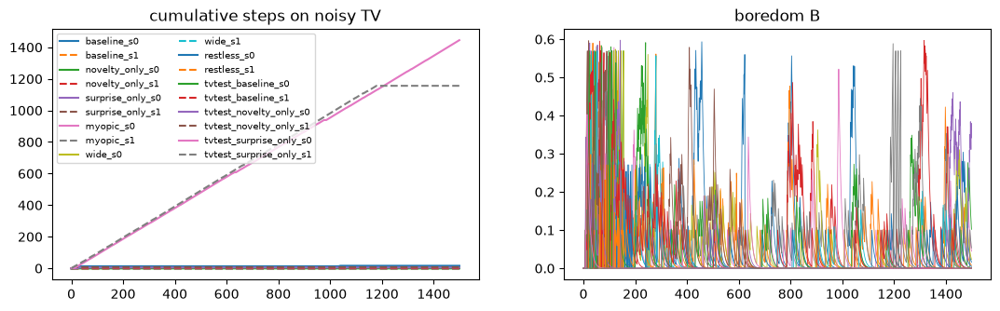

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for k, s in steps.items():
    if k.startswith('random'): continue
    axes[0].plot(s.step, s.tv.cumsum(), label=k, ls='-' if k.endswith('_s0') else '--')
    axes[1].plot(s.step, s.B, lw=0.6, label=k)
axes[0].set_title('cumulative steps on noisy TV'); axes[0].legend(fontsize=7, ncol=2)
axes[1].set_title('boredom B'); plt.show()

## TV test (added)
The main runs rarely met the TV (7 of 1,814 tiles, 50 km from the start). In these runs baseline, novelty_only and surprise_only
start one step from the TV cluster, so exposure is guaranteed. If prediction error is the trap, surprise_only should stay.

In [11]:
tvt = stats.loc[[r for r in stats.index if r.startswith('tvtest_')], ['unique', 'tv_steps', 'tv_unique', 'first_tv', 'max_tv_dwell', 'bored_events', 'cloud_vs_base']]
tvt

,unique,tv_steps,tv_unique,first_tv,max_tv_dwell,bored_events,cloud_vs_base
run,,,,,,,
tvtest_baseline_s0,310,0.000,0,-1,0,5,1.090
tvtest_baseline_s1,380,0.000,0,-1,0,3,1.103
tvtest_novelty_only_s0,219,0.003,3,21,2,1,1.303
tvtest_novelty_only_s1,236,0.005,5,3,7,2,1.462
tvtest_surprise_only_s0,32,0.963,7,0,166,0,0.000
tvtest_surprise_only_s1,82,0.771,7,0,266,4,0.759


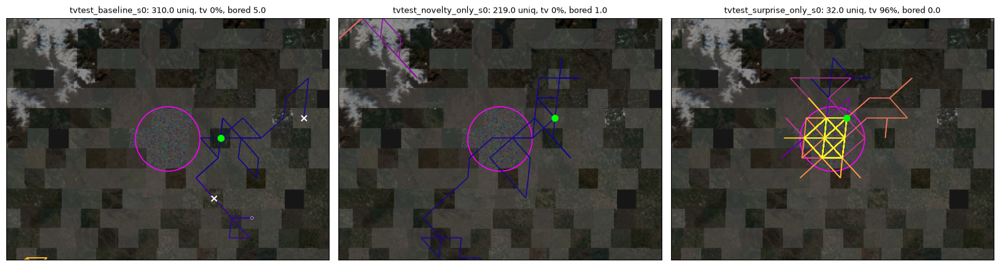

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, t in zip(axes, ['tvtest_baseline_s0', 'tvtest_novelty_only_s0', 'tvtest_surprise_only_s0']):
    if t not in steps: continue
    path_map(ax, t)
    ax.set_xlim(tvx - 80, tvx + 80); ax.set_ylim(tvy - 60, tvy + 60)
fig.tight_layout(); plt.show()

## Favourite tiles
Curious agents dwell: a few tiles get dozens of visits. Which tiles, and why (mean z-scores of the chosen tile over its visits)?

,top10_share,tiles_ge10_visits,share_on_ge10,immediate_return
run,,,,
baseline_s0,0.188,30,0.354,0.290
novelty_only_s0,0.239,36,0.507,0.321
surprise_only_s0,0.787,16,0.858,0.595
myopic_s0,0.267,34,0.479,0.285
wide_s0,0.179,35,0.407,0.252
random_s0,0.067,6,0.043,0.182


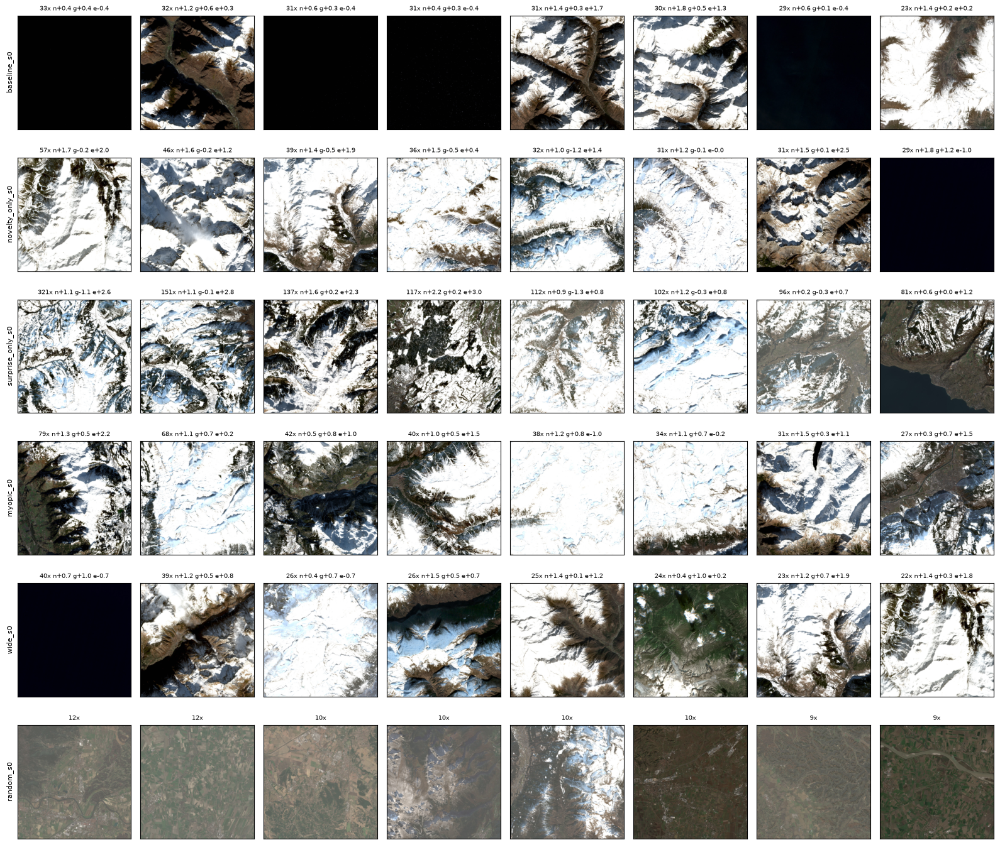

In [13]:
rows, ims = [], []
for k in ['baseline_s0', 'novelty_only_s0', 'surprise_only_s0', 'myopic_s0', 'wide_s0', 'random_s0']:
    if k not in steps: continue
    s = steps[k]; vc = s.tile_idx.value_counts()
    rows.append({'run': k, 'top10_share': vc.iloc[:10].sum() / len(s), 'tiles_ge10_visits': int((vc >= 10).sum()),
                 'share_on_ge10': vc[vc >= 10].sum() / len(s), 'immediate_return': (s.tile_idx.values[2:] == s.tile_idx.values[:-2]).mean()})
    top = vc.index[:8]
    v = s[s.tile_idx.isin(top)]
    ims.append((k, top, vc, v.groupby('tile_idx')[['n_z', 'g_z', 'e_z']].mean()))
display(pd.DataFrame(rows).set_index('run'))
fig, axes = plt.subplots(len(ims), 8, figsize=(16, 2.3 * len(ims)))
for r, (k, top, vc, z) in enumerate(ims):
    for c, t in enumerate(top):
        ax = axes[r, c]; ax.imshow(tiles[t]); ax.set_xticks([]); ax.set_yticks([])
        zz = z.loc[t] if t in z.index else None
        lab = f"{vc[t]}x" + (f" n{zz.n_z:+.1f} g{zz.g_z:+.1f} e{zz.e_z:+.1f}" if zz is not None and not np.isnan(zz.n_z) else '')
        ax.set_title(lab, fontsize=7)
    axes[r, 0].set_ylabel(k, fontsize=8)
fig.tight_layout(); plt.show()

## Seed divergence
Jaccard overlap of visited tile sets between seed 0 and seed 1, and first step where the paths differ.

In [14]:
rows = []
for tname in temps:
    a, b = steps.get(f'{tname}_s0'), steps.get(f'{tname}_s1')
    if a is None or b is None: continue
    A, Bs = set(a.tile_idx), set(b.tile_idx)
    diff = np.flatnonzero(a.tile_idx.values != b.tile_idx.values)
    rows.append({'temperament': tname, 'jaccard': len(A & Bs) / len(A | Bs), 'first_diff_step': int(diff[0]) if len(diff) else -1})
pd.DataFrame(rows).set_index('temperament')

,jaccard,first_diff_step
temperament,,
random,0.186,0
baseline,0.234,0
novelty_only,0.107,0
surprise_only,0.113,0
myopic,0.158,0
wide,0.203,0
restless,0.044,0
tvtest_baseline,0.053,1
tvtest_novelty_only,0.362,0


## Daydreams at bored events (decoded from latents near the archive's sparsest point)

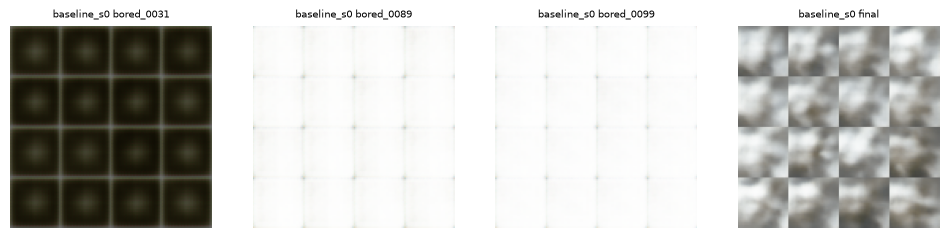

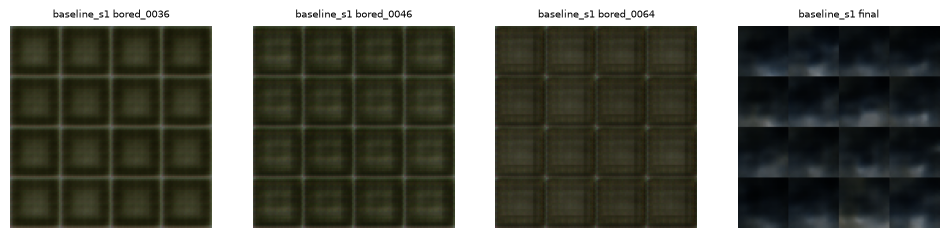

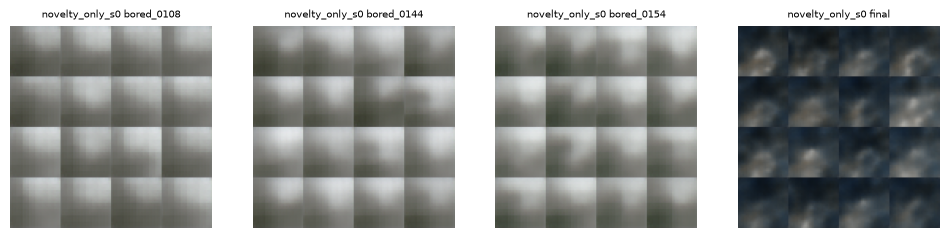

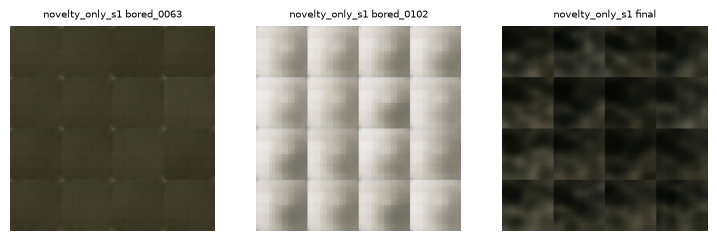

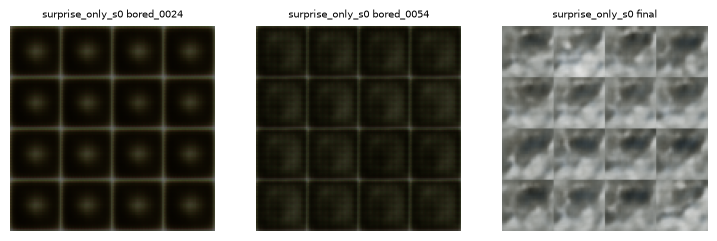

...

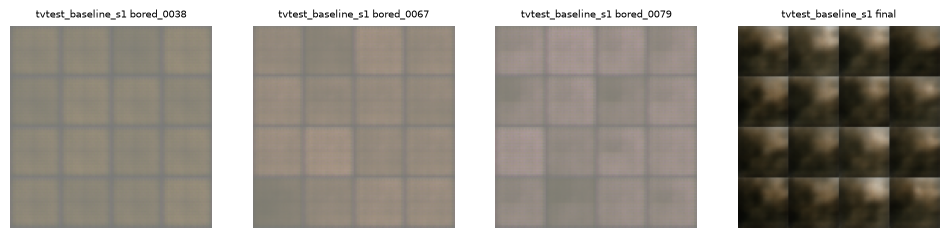

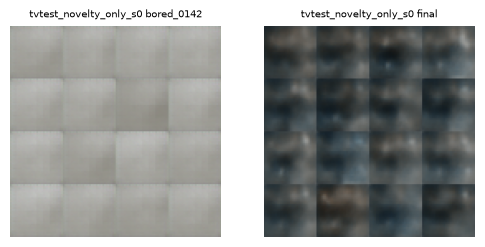

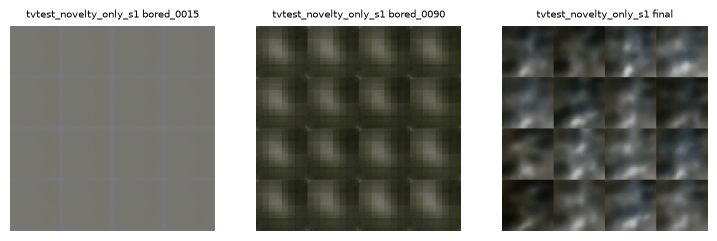

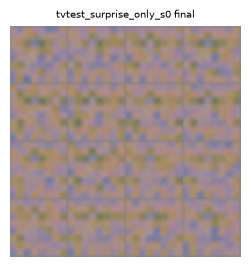

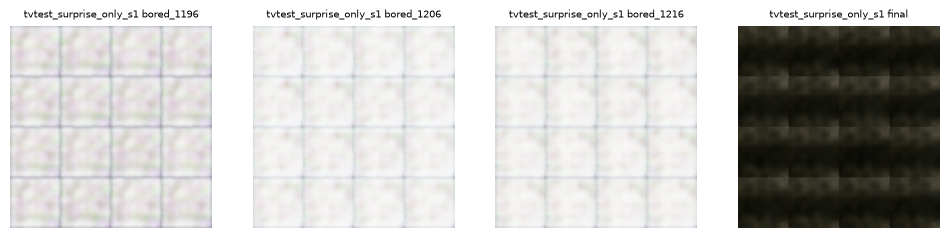

In [15]:
for p in runs:
    dd = sorted((p/'daydreams').glob('*.png'))
    if not dd: continue
    show = dd[:3] + ([dd[-1]] if len(dd) > 3 else [])
    fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3))
    for ax, f in zip(np.atleast_1d(axes), show):
        ax.imshow(Image.open(f)); ax.set_title(f'{p.name} {f.stem}', fontsize=7); ax.axis('off')
    plt.show()

## Gate 1 checks (computed)

In [16]:
r = gm.loc['random'] if 'random' in gm.index else None
checks = {}
if r is not None:
    d = {t: {c: gm.loc[t, c] / r[c] if r[c] else np.nan for c in ['unique', 'rg_km', 'revisit_rate']} for t in gm.index if t != 'random'}
    checks['(a) agent vs random (ratios: unique, rg, revisit)'] = pd.DataFrame(d).T.round(2).to_dict('index')
if {'baseline', 'novelty_only'} <= set(gm.index):
    checks['(b) tv share baseline vs novelty_only'] = (round(gm.loc['baseline', 'tv_steps'], 3), round(gm.loc['novelty_only', 'tv_steps'], 3))
    checks['(b) real-cloud ratio baseline vs novelty_only'] = (round(gm.loc['baseline', 'cloud_vs_base'], 2), round(gm.loc['novelty_only', 'cloud_vs_base'], 2))
for k, v in checks.items(): print(k, v)

(a) agent vs random (ratios: unique, rg, revisit) {'baseline': {'unique': 0.77, 'rg_km': 1.24, 'revisit_rate': 1.14}, 'novelty_only': {'unique': 0.51, 'rg_km': 1.17, 'revisit_rate': 1.29}, 'surprise_only': {'unique': 0.2, 'rg_km': 0.5, 'revisit_rate': 1.47}, 'myopic': {'unique': 0.61, 'rg_km': 1.37, 'revisit_rate': 1.23}, 'wide': {'unique': 0.7, 'rg_km': 1.05, 'revisit_rate': 1.18}, 'restless': {'unique': 0.6, 'rg_km': 1.09, 'revisit_rate': 1.24}, 'tvtest_baseline': {'unique': 0.62, 'rg_km': 1.17, 'revisit_rate': 1.22}, 'tvtest_novelty_only': {'unique': 0.41, 'rg_km': 0.92, 'revisit_rate': 1.35}, 'tvtest_surprise_only': {'unique': 0.1, 'rg_km': 0.44, 'revisit_rate': 1.53}}
(b) tv share baseline vs novelty_only (np.float64(0.005), np.float64(0.0))
(b) real-cloud ratio baseline vs novelty_only (np.float64(1.27), np.float64(1.04))


## Observations
*(filled in after running; see `notes/observations.md`)*